# Q, K y V dentro de Aya-101, paso a paso

Este notebook toma una historia sintética, le pregunta a Aya-101 por una variable y sigue los tensores reales: del texto a los tokens, de los tokens a los vectores, y de ahí a Q, K y V en una capa del encoder y en la atención cruzada del decoder. Termina en la palabra que elige el modelo.

Antes de empezar, en **Entorno de ejecución → Cambiar tipo de entorno de ejecución**, elige **T4 GPU**. Para clonar el repo privado hace falta el secret `GITHUB_TOKEN` (ver `notebooks/despliegue_colab.ipynb`, celda 2).

Al terminar, descarga el notebook con sus salidas (**Archivo → Descargar → .ipynb**) para guardarlo en el repo.

## 1. Preparar el entorno

In [1]:
# Sirve en Colab y en una copia local del repo
import os
import subprocess
import sys

REPO_URL = "https://github.com/joan999/aya101_historias_clinicas.git"
RAMA = "main"   # rama que se clona
EN_COLAB = "google.colab" in sys.modules


def token_github():
    """Lee el token de los Secrets de Colab. Si no está, devuelve None."""
    try:
        from google.colab import userdata
        return userdata.get("GITHUB_TOKEN")
    except Exception as error:
        print("Sin token de GitHub:", type(error).__name__)
        return None


def git(*args, token=None, cwd=None):
    """Corre git y tapa el token en lo que imprime."""
    resultado = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True,
                               env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    texto = (resultado.stdout + resultado.stderr).strip()
    if token:
        texto = texto.replace(token, "***")
    if texto:
        print(texto)
    if resultado.returncode != 0:
        raise RuntimeError("git falló: revisa el secret GITHUB_TOKEN y que el token tenga acceso al repo")


if EN_COLAB:
    token = token_github()
    url = REPO_URL.replace("https://", f"https://x-access-token:{token}@") if token else REPO_URL
    carpeta = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if os.path.exists(carpeta):
        git("pull", "-q", url, RAMA, token=token, cwd=carpeta)
    else:
        git("clone", "-q", "--branch", RAMA, url, carpeta, token=token)
        git("remote", "set-url", "origin", REPO_URL, cwd=carpeta)
    os.chdir(carpeta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.24.0",
                    "accelerate==1.16.0", "bitsandbytes==0.50.2", "pymupdf==2.1"], check=True)
elif not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")   # fuera de Colab se usa la carpeta del repo
sys.path.insert(0, os.getcwd())
print("Carpeta del proyecto:", os.getcwd())

Carpeta del proyecto: /content/aya101_historias_clinicas


## 2. Cargar Aya-101

La primera vez descarga 51,7 GB y cuantiza el modelo a 4 bits; tarda varios minutos.

In [2]:
import time

import torch

from src.config import MODELO_ID
from src.modelo import cargar_modelo

inicio = time.time()
tokenizador, modelo = cargar_modelo(MODELO_ID)
print(f"Modelo: {MODELO_ID} | descarga y carga: {time.time() - inicio:.0f} s")
if torch.cuda.is_available():
    usada = torch.cuda.memory_allocated()
    total = torch.cuda.get_device_properties(0).total_memory
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM del modelo cargado: {usada / 1e9:.2f} GB ({usada / 1024**3:.2f} GiB) de {total / 1e9:.1f} GB")

config.json:   0%|          | 0.00/836 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/833 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors.index.json: reconstructing file:   0%|          |  0.00B / 50.6kB            

model.safetensors.index.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

Modelo: CohereLabs/aya-101 | descarga y carga: 826 s
GPU: Tesla T4
VRAM del modelo cargado: 13.11 GB (12.21 GiB) de 15.6 GB


## 3. La entrada

Se usa la estrategia de una pregunta por variable. `CASO`, `VARIABLE` y `VALOR_EN_TEXTO` se pueden cambiar; `VALOR_EN_TEXTO` es cómo aparece el dato dentro de la historia y sirve en la sección 6.

In [3]:
import json
from pathlib import Path

import pandas as pd

from src.config import VARIABLES
from src.inferencia import inferir
from src.prompts import prompt_por_variable

CASO = "caso_1.txt"
VARIABLE = "hba1c_pct"
VALOR_EN_TEXTO = "7,4"

historia = Path("ejemplos_hc", CASO).read_text(encoding="utf-8").strip()
assert VALOR_EN_TEXTO in historia, "VALOR_EN_TEXTO no aparece en la historia"
tipo, pregunta = next((t, p) for clave, t, p in VARIABLES if clave == VARIABLE)
prompt = prompt_por_variable(historia, pregunta, tipo)
r = inferir(tokenizador, modelo, [prompt], historia, 20)[0]
esperado = json.loads(Path("ejemplos_hc/esperados.json").read_text(encoding="utf-8"))[CASO][VARIABLE]
print(prompt)
print("\nRespuesta del modelo:", repr(r["texto"]), "| valor esperado:", esperado)

Lee la historia clínica y responde la pregunta. Responde solo con el número, sin unidades. Si el dato no aparece, responde: No registrado.

Historia clínica:
HISTORIA CLÍNICA SINTÉTICA. DATOS FICTICIOS.
Paciente: Juan Pérez. CC 00000000. Edad: 62 años. Sexo: masculino.
Motivo de consulta: control de riesgo cardiovascular.
Antecedentes: hipertensión arterial diagnosticada en 2018. Diabetes mellitus tipo 2 desde 2020. Niega enfermedad renal conocida.
Examen físico: TA 138/84 mmHg, FC 76 lpm, peso 76 kg, talla 1,68 m.
Paraclínicos: creatinina sérica 1,15 mg/dL, HbA1c 7,4 %.
Tratamiento actual: losartán 50 mg cada 12 horas y metformina 850 mg cada 12 horas.
Plan: continuar manejo y control en 3 meses.

Pregunta: ¿Cuál es el valor de hemoglobina glicosilada (HbA1c) en %?
Respuesta:

Respuesta del modelo: 'El valor de hemoglobina glicosilada (HbA1c) en % es' | valor esperado: 7.4


## 4. Del texto al tensor

El tokenizador parte el prompt en subpalabras y cada una pasa a un vector. T5 no suma un vector de posición en este punto: la posición entra después, como un sesgo dentro de la atención.

In [4]:
ids = r["ids_entrada"]
print("input_ids:", tuple(ids[None].shape), f"(1 prompt de {len(ids)} tokens)")
display(pd.DataFrame({"token": r["tokens_entrada"][:20], "id": ids[:20].tolist()}).T)

dispositivo = modelo.get_input_embeddings().weight.device
with torch.no_grad():
    vectores = modelo.get_input_embeddings()(ids[None].to(dispositivo))
print("Embeddings:", tuple(vectores.shape), f"(cada token es un vector de {vectores.shape[-1]} números)")
print("Tamaño del vocabulario:", modelo.config.vocab_size)

input_ids: (1, 250) (1 prompt de 250 tokens)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
token,▁Lee,▁la,▁historia,▁c,línic,a,▁,y,▁responde,▁la,▁pregunta,.,▁Respond,e,▁solo,▁con,▁el,▁,número,","
id,11127,283,8664,317,49090,262,259,276,64374,283,22056,260,146352,265,3607,450,362,259,10940,261


Embeddings: (1, 250, 4096) (cada token es un vector de 4096 números)
Tamaño del vocabulario: 250112


## 5. Self-attention del encoder, capa 1

Se repite el paso del modelo con ganchos en la capa 1 y se guardan X, Q, K y V. Después se rehace la cuenta a mano y se compara con lo que calculó el modelo.

In [5]:
from src.qkv import capturar_qkv, modulo_atencion

c = capturar_qkv(modelo, r["ids_entrada"], r["ids_decoder"], "Self-attention del encoder", 0)
tokens = r["tokens_entrada"]
print("X  (entrada de la capa, ya con RMSNorm):", tuple(c["x_q"].shape))
print("Q = X·W_Q:", tuple(c["q"].shape), "-> por cabezas:", tuple(c["q_cabezas"].shape), f"({c['cabezas']} cabezas de {c['d_kv']})")
print("K = X·W_K:", tuple(c["k"].shape), "-> por cabezas:", tuple(c["k_cabezas"].shape))
print("V = X·W_V:", tuple(c["v"].shape), "-> por cabezas:", tuple(c["v_cabezas"].shape))
print("Puntajes = Q·Kᵀ + sesgo:", tuple(c["puntajes"].shape), f"| escala {c['escala']}: no divide por la raíz de {c['d_kv']}")
print("Pesos = softmax(puntajes):", tuple(c["pesos"].shape))
print(f"Comprobación: diferencia máxima entre la cuenta a mano y los pesos del modelo = {c['diferencia']:.1e}")

# Una sola celda de la matriz, cabeza 1: el primer token mirando al segundo
h, i, j = 0, 0, 1
producto = float(c["q_cabezas"][0, h, i] @ c["k_cabezas"][0, h, j])
print(f"\nCabeza 1, «{tokens[i]}» mirando a «{tokens[j]}»: Q·K = {producto:.3f}; "
      f"sesgo = {float(c['sesgo'][0, h, i, j]):.3f}; puntaje = {float(c['puntajes'][0, h, i, j]):.3f}")

X  (entrada de la capa, ya con RMSNorm): (1, 250, 4096)
Q = X·W_Q: (1, 250, 4096) -> por cabezas: (1, 64, 250, 64) (64 cabezas de 64)
K = X·W_K: (1, 250, 4096) -> por cabezas: (1, 64, 250, 64)
V = X·W_V: (1, 250, 4096) -> por cabezas: (1, 64, 250, 64)
Puntajes = Q·Kᵀ + sesgo: (1, 64, 250, 250) | escala 1.0: no divide por la raíz de 64
Pesos = softmax(puntajes): (1, 64, 250, 250)
Comprobación: diferencia máxima entre la cuenta a mano y los pesos del modelo = 2.4e-02

Cabeza 1, «▁Lee» mirando a «▁la»: Q·K = -0.259; sesgo = -5.000; puntaje = -5.259


El sesgo de posición depende solo de la distancia entre dos tokens. T5 agrupa las distancias: cada distancia corta tiene su propio grupo y las largas comparten grupos. Esta tabla muestra el grupo de cada par de posiciones, para las 12 primeras. Solo la capa 1 tiene la tabla de sesgos; las otras capas del encoder reutilizan el mismo sesgo.

,0,1,2,3,4,5,6,7,8,9,10,11
0,0,17,18,19,20,21,22,23,24,24,24,24
1,1,0,17,18,19,20,21,22,23,24,24,24
2,2,1,0,17,18,19,20,21,22,23,24,24
3,3,2,1,0,17,18,19,20,21,22,23,24
4,4,3,2,1,0,17,18,19,20,21,22,23
5,5,4,3,2,1,0,17,18,19,20,21,22
6,6,5,4,3,2,1,0,17,18,19,20,21
7,7,6,5,4,3,2,1,0,17,18,19,20
8,8,7,6,5,4,3,2,1,0,17,18,19
9,8,8,7,6,5,4,3,2,1,0,17,18


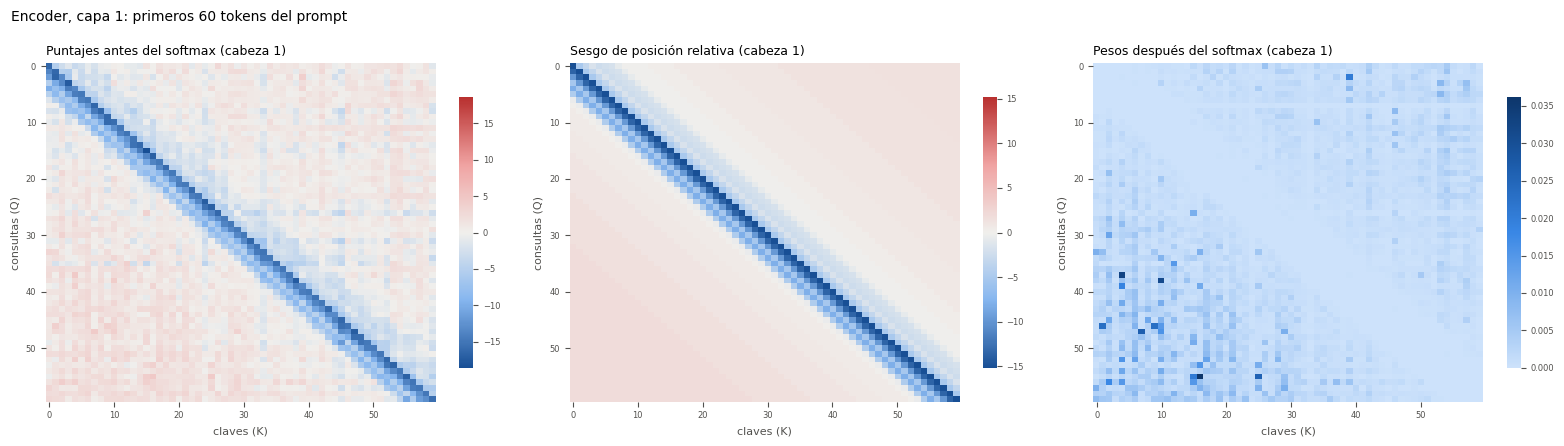

In [6]:
import matplotlib.pyplot as plt

from src.graficos import mapa_calor

capa_1 = modulo_atencion(modelo, "Self-attention del encoder", 0)
posiciones = torch.arange(12)
grupos = capa_1._relative_position_bucket(
    posiciones[None, :] - posiciones[:, None], bidirectional=True,
    num_buckets=modelo.config.relative_attention_num_buckets,
    max_distance=modelo.config.relative_attention_max_distance,
)
display(pd.DataFrame(grupos.numpy()))

n = min(60, len(tokens))
figura, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
mapa_calor(ejes[0], figura, c["puntajes"][0, 0, :n, :n], "Puntajes antes del softmax (cabeza 1)", tokens[:n], tokens[:n], True)
mapa_calor(ejes[1], figura, c["sesgo"][0, 0, :n, :n], "Sesgo de posición relativa (cabeza 1)", tokens[:n], tokens[:n], True)
mapa_calor(ejes[2], figura, c["pesos"][0, 0, :n, :n], "Pesos después del softmax (cabeza 1)", tokens[:n], tokens[:n], False)
figura.suptitle(f"Encoder, capa 1: primeros {n} tokens del prompt", x=0.01, ha="left", fontsize=10)
figura.tight_layout()
plt.show()

## 6. Atención cruzada: dónde mira el decoder al escribir la respuesta

En la atención cruzada, Q sale del decoder (lo que va escribiendo) y K y V salen de la salida del encoder (el prompt ya leído). Para cada una de las capas del decoder se mide cuánta atención pone el primer token de la respuesta sobre los tokens de `VALOR_EN_TEXTO`, con el promedio de las cabezas.

Tokens del valor: ['▁7,4']


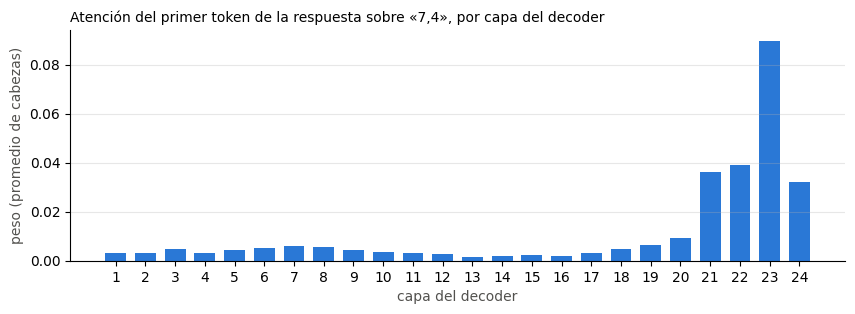

Capa con más atención sobre el valor: 23 (peso 0.090)


In [7]:
from src.graficos import COLOR_ESTRATEGIA, TEXTO_SECUNDARIO

with torch.no_grad():
    paso = modelo(input_ids=r["ids_entrada"][None].to(dispositivo),
                  decoder_input_ids=r["ids_decoder"][None].to(dispositivo), output_attentions=True)

# Posiciones del prompt que cubren el valor dentro de la historia
desplazamientos = tokenizador(prompt, return_offsets_mapping=True)["offset_mapping"]
assert len(desplazamientos) == len(r["ids_entrada"])
inicio_valor = prompt.find(historia) + historia.find(VALOR_EN_TEXTO)
fin_valor = inicio_valor + len(VALOR_EN_TEXTO)
pos_valor = [k for k, (a, b) in enumerate(desplazamientos) if b > inicio_valor and a < fin_valor and b > a]
print("Tokens del valor:", [tokens[k] for k in pos_valor])

masa = torch.stack([capa[0, :, 0, pos_valor].float().sum(-1).mean().cpu() for capa in paso.cross_attentions])
capa_max = int(masa.argmax()) + 1
figura, eje = plt.subplots(figsize=(10, 3))
eje.bar(range(1, len(masa) + 1), masa.numpy(), color=COLOR_ESTRATEGIA["Una pregunta por variable"], width=0.7)
eje.set_title(f"Atención del primer token de la respuesta sobre «{VALOR_EN_TEXTO}», por capa del decoder", fontsize=10, loc="left")
eje.set_xlabel("capa del decoder", color=TEXTO_SECUNDARIO)
eje.set_ylabel("peso (promedio de cabezas)", color=TEXTO_SECUNDARIO)
eje.set_xticks(range(1, len(masa) + 1))
eje.grid(axis="y", alpha=0.3)
eje.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"Capa con más atención sobre el valor: {capa_max} (peso {float(masa.max()):.3f})")

Recorrido de esa capa: las formas de Q, K y V muestran que las consultas vienen del decoder y las claves del encoder.

In [8]:
c2 = capturar_qkv(modelo, r["ids_entrada"], r["ids_decoder"], "Atención cruzada (decoder → encoder)", capa_max - 1)
print("Q (del decoder):", tuple(c2["q_cabezas"].shape), "| K (del encoder):", tuple(c2["k_cabezas"].shape), "| V (del encoder):", tuple(c2["v_cabezas"].shape))
print("Puntajes:", tuple(c2["puntajes"].shape), "| sesgo de posición en la atención cruzada:", float(c2["sesgo"].abs().max()))
print(f"Comprobación: diferencia máxima = {c2['diferencia']:.1e}")

pesos = c2["pesos"][0].mean(dim=0)   # promedio de cabezas: [tokens del decoder, tokens del prompt]
top = pesos[0].argsort(descending=True)[:10]
print(f"\nLos 10 tokens del prompt que más mira el primer token de la respuesta en la capa {capa_max}:")
display(pd.DataFrame({"posición": top.tolist(), "token": [tokens[k] for k in top.tolist()],
                      "peso": pesos[0, top].numpy().round(4)}))

Q (del decoder): (1, 64, 20, 64) | K (del encoder): (1, 64, 250, 64) | V (del encoder): (1, 64, 250, 64)
Puntajes: (1, 64, 20, 250) | sesgo de posición en la atención cruzada: 0.0
Comprobación: diferencia máxima = 4.5e-03

Los 10 tokens del prompt que más mira el primer token de la respuesta en la capa 23:


,posición,token,peso
0,179,"▁7,4",0.0898
1,79,▁masculin,0.0581
2,57,IOS,0.0456
3,131,físic,0.0431
4,180,▁%,0.0423
5,18,número,0.0394
6,49,TÉ,0.0391
7,71,dad,0.0365
8,90,ries,0.0249
9,221,:,0.0218


## 7. De la última capa a la palabra

La salida del decoder pasa por `lm_head`, que da un puntaje (logit) para cada token del vocabulario. Con decodificación greedy el modelo elige el de mayor probabilidad.

In [9]:
logits = paso.logits
print("logits:", tuple(logits.shape), "(tokens del decoder × vocabulario)")
probabilidades = logits[0, 0].float().softmax(dim=-1)
mejores = probabilidades.topk(5)
display(pd.DataFrame({"token": tokenizador.convert_ids_to_tokens(mejores.indices.tolist()),
                      "probabilidad": mejores.values.cpu().numpy().round(4)}))
print("Primer token que generó el modelo:", r["tokens_salida"][:1])

logits: (1, 20, 250112) (tokens del decoder × vocabulario)


,token,probabilidad
0,▁El,0.5531
1,"▁7,4",0.1809
2,▁7.4,0.0714
3,▁No,0.0620
4,▁La,0.0255


Primer token que generó el modelo: ['▁El']


## 8. Resumen de formas en todo el modelo

`n` es el número de tokens del prompt y `t` el de tokens del decoder en este ejemplo.

In [10]:
cfg = modelo.config
n, t = len(r["ids_entrada"]), len(r["ids_decoder"])
H, dkv, d, dff, V = cfg.num_heads, cfg.d_kv, cfg.d_model, cfg.d_ff, cfg.vocab_size
display(pd.DataFrame([
    ("Prompt tokenizado", f"[1, {n}]"),
    ("Embeddings", f"[1, {n}, {d}]"),
    (f"Encoder × {cfg.num_layers} capas: Q, K, V por cabezas", f"[1, {H}, {n}, {dkv}]"),
    ("Encoder: puntajes y pesos de atención", f"[1, {H}, {n}, {n}]"),
    ("Encoder: FFN (gated-GELU) wi_0 y wi_1 → wo", f"[1, {n}, {dff}] → [1, {n}, {d}]"),
    ("Salida del encoder", f"[1, {n}, {d}]"),
    ("Entrada del decoder", f"[1, {t}]"),
    (f"Decoder × {cfg.num_decoder_layers} capas: self-attention", f"[1, {H}, {t}, {t}]"),
    ("Decoder: atención cruzada (Q del decoder, K y V del encoder)", f"[1, {H}, {t}, {n}]"),
    ("Salida del decoder", f"[1, {t}, {d}]"),
    ("lm_head → logits", f"[1, {t}, {V}]"),
], columns=["paso", "forma"]))

,paso,forma
0,Prompt tokenizado,"[1, 250]"
1,Embeddings,"[1, 250, 4096]"
2,"Encoder × 24 capas: Q, K, V por cabezas","[1, 64, 250, 64]"
3,Encoder: puntajes y pesos de atención,"[1, 64, 250, 250]"
4,Encoder: FFN (gated-GELU) wi_0 y wi_1 → wo,"[1, 250, 10240] → [1, 250, 4096]"
5,Salida del encoder,"[1, 250, 4096]"
6,Entrada del decoder,"[1, 20]"
7,Decoder × 24 capas: self-attention,"[1, 64, 20, 20]"
8,"Decoder: atención cruzada (Q del decoder, K y ...","[1, 64, 20, 250]"
9,Salida del decoder,"[1, 20, 4096]"


## 9. Memoria usada

In [11]:
if torch.cuda.is_available():
    print(f"VRAM máxima durante el notebook: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

VRAM máxima durante el notebook: 14.13 GB
